In [3]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller, coint
import yfinance as yf
import sklearn
from sklearn.model_selection import train_test_split
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
import pyfolio as pf

import warnings
warnings.filterwarnings("ignore")


# 1 Introduction to Cointegration

Cointegration is known as a model for a long-term relationship, which is a shortcut taken for the ease of explanation. It is illustrative to contrast cointegration and correlation, while, in fact, multiple scenarios are possible: correlated series can run away from each other, while cointegrated series might be seemingly unrelated. Correlation suffers from shortcomings of its measurement: it refects co-movement on the small timescale only and, when measured over the long term, compounds to abnormally high values. Correlation among equities is usually range-bound, so it is a fundamentally uncertain parameter. Cointegration too have an element of uncertainty: the spread produced by cointegrated time series is stationary and mean-reverting around some
linear equilibrium level. The tie-in among cointegrated series is not exact.

Economic theory suggests that many time series datasets will move together, fluctuating around a long-run equilibrium. In econometrics and statistics, this long-run equilibrium is tested and measured using the concept of cointegration.

Cointegration occurs when two or more nonstationary time series:

- Have a long-run equilibrium.
- Move together in such a way that their linear combination results in a stationary time series. 
- Share an underlying common stochastic trend.

To understand the mathematics of cointegration, let's consider a group of time series, which is composed of two separate time series

$$y_1 = (y_{11}, y_{12}, \ldots, y_{1t})$$
$$y_2 = (y_{21}, y_{22}, \ldots, y_{2t})$$
$$y_3 = (y_{31}, y_{32}, \ldots, y_{3t})$$

All three series are nonstationary time series.
Cointegration implies that while $y_1$,$y_2$ and $y_3$ are independently nonstationary, they can be combined in a way that their linear combination is stationary :

$$\beta_{coint} Y_t = \beta_1 y_{1t} + \beta_2 y_{2t} + \beta_3 y_{3t} \sim I(0)$$

**The Cointegrating Vector**
In the context of cointegration $\beta_{coint} $ is commonly known as the cointegrating vector. This vector:

- Dictates how cointegrating series are combined.
- Does not have to be unique - there can be multiple ways of cointegrating.

Normalization Because there can be multiple cointegrating vectors that fit the same economic model, we must impose identification restrictions to normalize the cointegrating vector for estimation.

A common normalization of the cointegrating vector is to set $\beta_{coint} = ( 1,  -\beta_2, \ldots, -\beta_N)$
. For example, applying these restrictions to our earlier system yields

$$\beta_{coint} Y_t = y_{1t} - \beta_2 y_{2t} - \beta_3 y_{3t} \sim I(0)$$

Part of the appeal of this normalization is that it can be rewritten in a standard regression form

$$ e_t = y_{1t} - \beta_2 y_{2t} - \beta_3 y_{3t}$$

$$ e_t = \beta_{coint} Y_t $$
where $e_t$is a stationary cointegrating error component which is also called spread

The spread is a stationary and autoregressive process, which gives it the mean reversion property. But it is not an integrated process, 'integrated of order zero'. In comparison, a non-stationary $y_{i,t}$ is 'integrated' because it can be decomposed into the infinite sum of residuals that are econometric moving averages.Building models of non-stationary time series by means of a regression|we will see below how regression for $y_t$ is a static model - requires a genuine long-run relationship among the series. **In the absence of a long-run run relationship, there is no way to tie the non-stationary variables to produce a stationary spread**. A spurious regression will show the high goodness of fit $R^2$ but it has been proven that its coefficients are random variables that do not converge to their true value of zero. Therefore, the common statistical inference fails in the special case of spurious regression. However, it is not possible to detect that without building a further model for cointegration.

# 2 Exporatory analysis to identify Coinegrated pairs

In [4]:
def find_cointegrated_pairs(data):
    n = data.shape[1]
    coint_score_matrix = np.zeros(shape = (n,n))
    p_value_matrix = np.zeros(shape = (n,n))
    pairs = []
    stocks = data.columns
    
    for i in range(n):
        for j in range(i+1, n):
            s1 = data[stocks[i]]
            s2 = data[stocks[j]]
            result = coint(s1,s2)                           
            score = result[0]                               
            p_value = result[1]
            coint_score_matrix[i,j] = score
            p_value_matrix[i,j] = p_value
            
            if p_value < 0.05:
                pairs.append((stocks[i],stocks[j]))
                
    return coint_score_matrix, p_value_matrix, pairs

In [34]:
tickers = ['JPM', 'BAC', 'C', 'GS', 'WFC', 'HSBC', 'MS', 'RY', 'UBS', 'IBN', 'BMO', 'HDB','TD','PNC','BNS','^GSPC']
df = yf.download(tickers = tickers, start='2015-01-01', end='2022-12-31',progress =False)
df = df['Close']

train_prices = df[:1600]
test_prices = df[1600:]

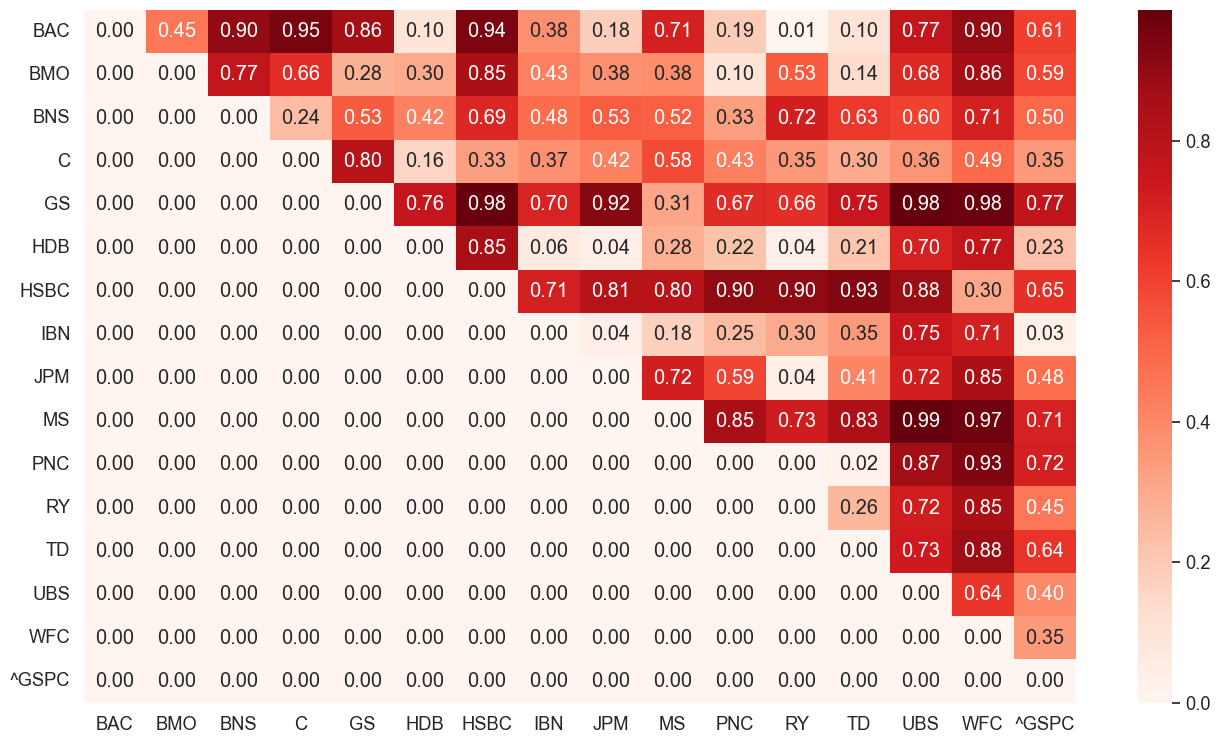

In [35]:
coint_score, pvalue, pairs = find_cointegrated_pairs(train_prices)
label_tickers = list(df.columns)

plt.figure(figsize =(16,9))
sns.set(font_scale =1.2)
sns.heatmap(pvalue,annot= True,cmap = 'Reds', fmt ='0.2f',cbar = True,xticklabels=label_tickers, yticklabels=label_tickers)               
plt.savefig('Latex Report/Figures/pair_identify.png')
plt.show()

Our first step is to decide the stock universe and identify the pairs with high correlation. It is very important that this is based on economic relationships such as companies with similar businesses, else it might be spurious. We have taken  constituents of US Financial Sector which are categorized as ‘FINANCIAL SERVICES’ companies. We take the daily closing price for these 15 stocks for roughly last 7 years and split the dataframe into test and training sets. This is to ensure that our decision to select a cointegrated pair is based on the training dataset and backtesting is done using out of sample test dataset

we have selcted stocks BAC(Bank of Americal Copr) and RY(Royal Bank of Canada) **as a potential candidate** for cointegration analysis since p -value from cointegraton test is small and less than 0.05 threshold 

# 3 Cointegration Analysis and Mean Reversion process

### 3.1 Stock Prices data

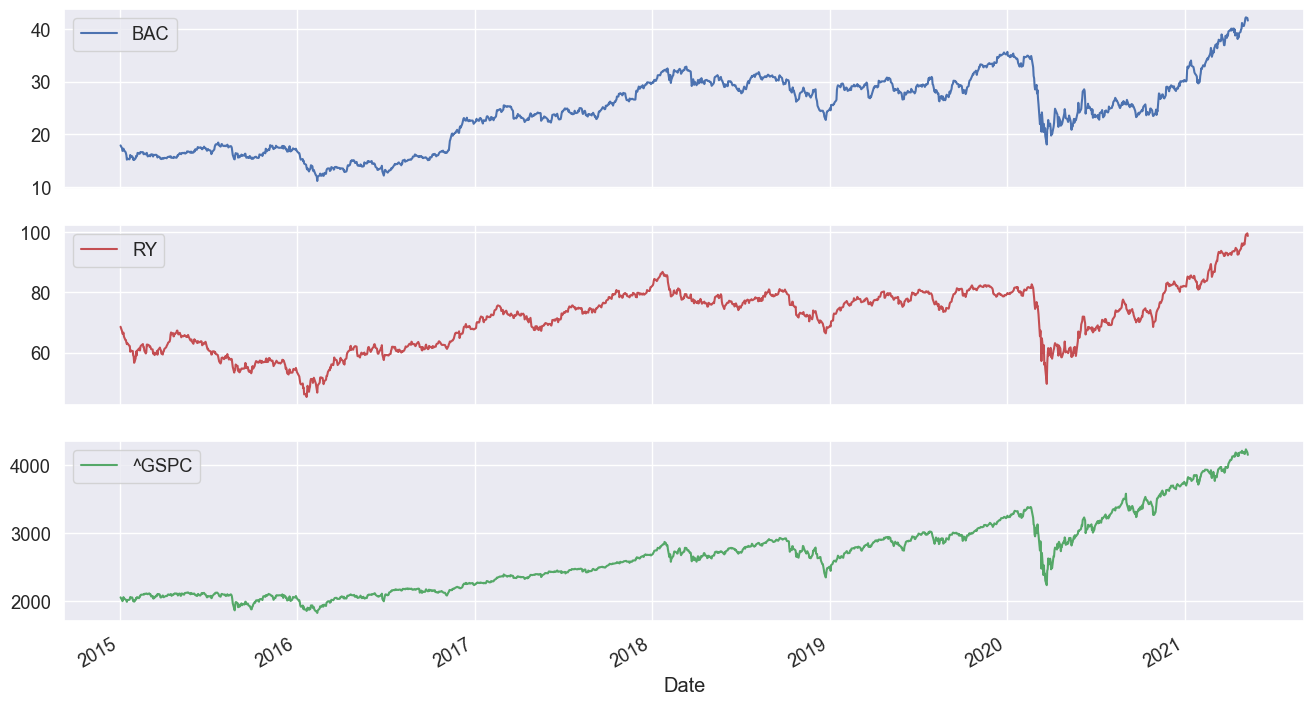

In [7]:
tickers = ['BAC','RY','^GSPC']
train_prices = train_prices[tickers]
test_prices = test_prices[tickers]

train_prices.plot(figsize=(16,9), color=('b', 'r', 'g'), subplots=True)
plt.savefig('Latex Report/Figures/stock_prices.png')
plt.show()

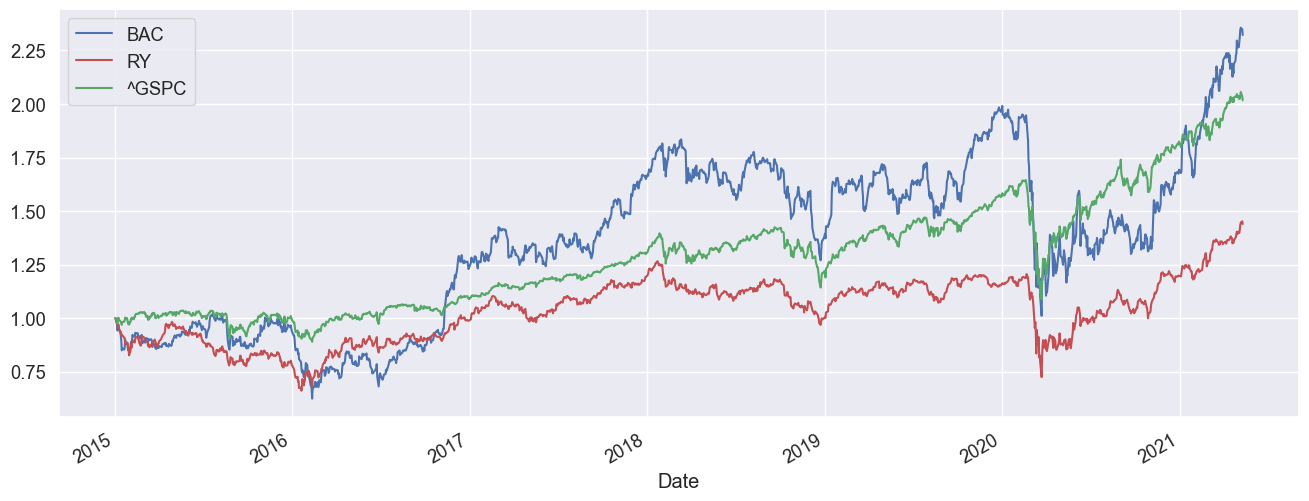

In [8]:
train_prices_norm = train_prices/train_prices.iloc[0]
test_prices_norm = test_prices/test_prices.iloc[0]

train_prices_norm.plot(figsize=(16,6), color=('b', 'r', 'g'))
plt.savefig('Latex Report/Figures/stock_prices_norm.png')
plt.show()

We split prices data for BAC and RY into train and test datasets along with S&P 500 index which will be used as a benchmark index for returns comparison & analysis.

Time series data are sequential in nature and are characterised by the correlation between observations. Classical cross-validation techniques such as KFold assume the samples are independent and identically distributed, and would result in poor estimates when applied on time series data.

To preserve the order and have training set occur prior to the test set, we split prices data in 80:20 ratio i.e. 80 for training set and 20 for test set sequentially. And therefore training set contains data from Jan'15 to May'21 and similarly, test set contains data from May'21 to Dec'22.

Below are the price charts of BAC, RY and S&P 500 for training set both in actual and normalized terms i.e. make day 1 prices as unit prices. On Cursory look at these charts, we can say that BAC and RY prices move together and seem cointegrated. However, we need to perform statistical tests to confirm this hypothesis.

Cointegration testing is sensitive to the initial value, normalising to start at one, also this allows comparison of P&L:

### 3.2 Stationarity check of daily returns 

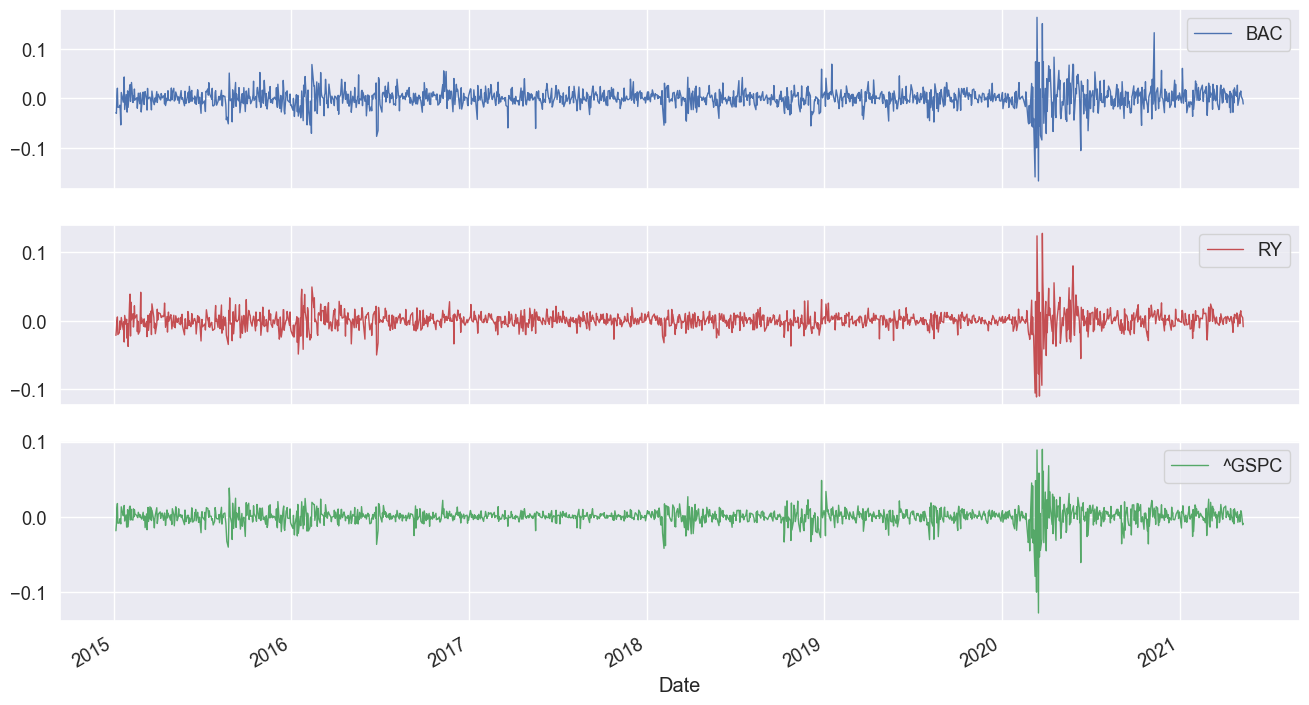

In [9]:
returns = np.log(train_prices).diff().dropna()
returns.plot(figsize=(16,9), color=('b', 'r', 'g'), subplots=True, linewidth=1)
plt.savefig('Latex Report/Figures/returns.png')
plt.show()

From the plots, it seems all three return time series - BAC, PNC and S&P 500 are stationary. However, we will perform Augmentd Dickey Fuller(ADF) test to confirm the same.

### Augmented Dickey Fuller(ADF) test

Dickey Fuller test is a statistical test that is used to check for stationarity in time series. This is a type of unit root test, through which we find if the time series is having any unit root. Unit root is a feature of time series that indicates if there is any stochastic trend in the time series that drives it away from its mean value. Presence of unit root makes a time series non-stationary and as a result it leads to difficulties in deriving statistical inferences from the time series and future predictions.

Dickey Fuller test assumes a AR(1) type time series model and it is represented mathematically as
The Dickey-Fuller test is testing if  $\phi = 0$

$$ y_t = \alpha + \beta t + \phi y_{t-1} + e_t $$

this can be written as :
$$\Delta y_t = y_t-y_{t-1}= \alpha + \beta t + \gamma y_{t-1} + e_t $$ 

where $\gamma = \phi -1 $ 

The Augmented Dickey-Fuller test allows for higher-order autoregressive processes by including  $\Delta y_{t-p}$ in the model. But our test is still if $\gamma =0 $
 
$$\Delta y_t = \alpha + \beta t + \gamma y_{t-1} + \delta_1 \Delta y_{t-1} + \delta_2 \Delta y_{t-2} + \dots $$

we drop constant drift term and timedependent trend term since these modifications can create temporary
dependency and give overfitted results. Additionally, we restrict number of lags to 1. Based on aforemenioned modifications, equation is as follows

$$\Delta y_t = \gamma y_{t-1} + \delta_1 \Delta y_{t-1} + e_t$$ 

**H0 (Null hypothesis)**: Time series data has unit root and is non-stationary, $\gamma = 0$ 

**H1 (Alternative hypothesis)** Time series data has no unit root and is stationary

We want to REJECT the null hypothesis for this test, so we want a p-value of less that 0.05 (or smaller).

### 3.2.1 Stationarity check for BAC log-returns time series - I(0) process

In [10]:
adf_test = adfuller(returns['BAC'])
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-12.518002,0.000000,8,1590


From Augmented Dickey-Fuller test output on BAC stock log-returns time series, we conclude that it is stationary since p-value is insignificant and not breaching ADF distribution threshold. And Hence, BAC log-returns timeseries is integrated process of order zero.

In [11]:
def createTable(df,caption,label,resizeFactor,reportName):
    tmp = df.to_latex(header = True,index = False, float_format = '%0.2f')
    tmp_list = tmp.splitlines()
    tmp = '\n'.join(tmp_list)
    with open('LaTeX Report/Tables/adf_BAC.tex', mode = 'w') as f:
        f.write('\\begin{table}[!ht] \n')
        f.write('\centering \n')
        f.write('\\resizebox{' + resizeFactor + '\\textwidth}{!} { \n')
        f.write(tmp)
        f.write('} \n')
        f.write('\\caption {' + caption + '} \n')
        f.write('\\label {' + caption + '} \n')
        f.write('\\end{table} \n')
        f.write('\\FloatBarrier')
        
createTable(adf_output,'ADF test output on BAC Returns','adf_BAC','0.7','adf_BAC')

### 3.2.2 Stationarity check for RY stock log-returns time series - I(0) process

In [12]:
adf_test = adfuller(returns['RY'])
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-11.957979,0.000000,8,1590


We performed similar Augmented Dickey-Fuller test on RY stock log-returns time series and conclude that it is stationary since p-value is insignificant and not breaching ADF distribution threshold. And Hence, RY log-returns timeseries is integrated process of order zero.

In [13]:
def createTable(df,caption,label,resizeFactor,reportName):
    tmp = df.to_latex(header = True,index = False, float_format = '%0.2f')
    tmp_list = tmp.splitlines()
    tmp = '\n'.join(tmp_list)
    with open('LaTeX Report/Tables/adf_RY.tex', mode = 'w') as f:
        f.write('\\begin{table}[!ht] \n')
        f.write('\centering \n')
        f.write('\\resizebox{' + resizeFactor + '\\textwidth}{!} { \n')
        f.write(tmp)
        f.write('} \n')
        f.write('\\caption {' + caption + '} \n')
        f.write('\\label {' + caption + '} \n')
        f.write('\\end{table} \n')
        f.write('\\FloatBarrier')
        
createTable(adf_output,'ADF test output on RY Returns','adf_RY','0.7','adf_RY')

### 3.2.3 Stationarity check for S&P 500 index log-returna time series - I(0) process

In [14]:
adf_test = adfuller(returns['^GSPC'])
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-12.381857,0.000000,8,1590


We performed similar Augmented Dickey-Fuller test on S&P 500 index log-returns time series and conclude that it is stationary since p-value is insignificant and not breaching ADF distribution threshold. And Hence, S&P 500 index log-returns timeseries is integrated process of order zero.

In [15]:
def createTable(df,caption,label,resizeFactor,reportName):
    tmp = df.to_latex(header = True,index = False, float_format = '%0.2f')
    tmp_list = tmp.splitlines()
    tmp = '\n'.join(tmp_list)
    with open('LaTeX Report/Tables/adf_S&P500.tex', mode = 'w') as f:
        f.write('\\begin{table}[!ht] \n')
        f.write('\centering \n')
        f.write('\\resizebox{' + resizeFactor + '\\textwidth}{!} { \n')
        f.write(tmp)
        f.write('} \n')
        f.write('\\caption {' + caption + '} \n')
        f.write('\\label {' + caption + '} \n')
        f.write('\\end{table} \n')
        f.write('\\FloatBarrier')
        
createTable(adf_output,'ADF test output on S&P500 Returns','adf_S&P500','0.7','adf_S&P500')

### 3.3 VAR Model fitting : Matrix form representation

VAR models (vector autoregressive models) are used for multivariate time series. The structure is that each variable is a linear function of past lags of itself and past lags of the other variables.

For a general example of a VAR(p) with k variables, see General matrix notation of a VAR(p).

A VAR(1) in three variables can be written in matrix form (more compact notation) as

$$\begin{pmatrix} {y}_{1t} \\ y_{2t} \\ y_{3t}\end{pmatrix} =   
\begin{pmatrix} a_{10} \\ a_{20} \\ a_{30} \end{pmatrix} + \begin{bmatrix} a_{11} & a_{12} & a_{13} \\ a_{21} & a_{22} & a_{23} \\ a_{31} & a_{32} & a_{33}\end{bmatrix}\begin{pmatrix} y_{1t-1} \\ y_{2t-1}  \\ y_{3t-1}\end{pmatrix} + 
\begin{pmatrix} \epsilon_{1t} \\ \epsilon_{2t} \\ \epsilon_{3t}
\end{pmatrix}$$

or, more compactly,
$$ y_t = A_0 + A_1 y_{t-1} + \epsilon_t,$$

where, $$y_t = \begin{pmatrix} y_{1t} \\ y_{2t} \\ y_{3t}\end{pmatrix}, A_0 = \begin{pmatrix} a_{10} \\ a_{20} \\ a_{30} \end{pmatrix}, A_1= \begin{bmatrix} a_{11} & a_{12} & a_{13} \\ a_{21} & a_{22} & a_{23} \\ a_{31} & a_{32} & a_{33}\end{bmatrix} \text{and   } \epsilon_t = \begin{pmatrix} \epsilon_{1t} \\ \epsilon_{2t} \\\epsilon_{3t} \end{pmatrix}.$$

Basically, such a model implies that everything depends on everything. But as can be seen from this formulation, each row can be written as a separate equation, so that 
$$ y_{1t} = a_{10} + a_{11} y_{1t-1} + a_{12} y_{2t-1} + a_{13} y_{3t-1} + \epsilon_{1t} $$
$$ y_{2t} = a_{20} + a_{21} y_{1t-1} + a_{22} y_{2t-1} + a_{23} y_{3t-1} + \epsilon_{2t} $$
$$ y_{3t} = a_{30} + a_{31} y_{1t-1} + a_{32} y_{2t-1} + a_{33} y_{3t-1} + \epsilon_{3t} $$

Hence, the VAR model can be rewritten as a series of individual ADL models as described above. In fact, it is possible to estimate VAR models by estimating each equation separately.

For our analysis, endogenous variables in VAR(1) model are log returns of BAC, RY and S&P500 stocks which are stationary in nature. And therefore, we can rewrite above equations as follows

$$ R^{BAC}_{t} = a_{10} + a_{11} R^{BAC}_{t-1} + a_{12} R^{RY}_{t-1} + a_{13} R^{SP500}_{t-1} + \epsilon_{1t} $$

$$ R^{RY}_{t} = a_{20} + a_{21} R^{BAC}_{t-1} + a_{22} R^{RY}_{t-1} + a_{23} R^{SP500}_{t-1} + \epsilon_{2t} $$

$$ R^{SP500}_{t} = a_{30} + a_{31} R^{BAC}_{t-1} + a_{32} R^{RY}_{t-1} + a_{33} R^{SP500}_{t-1} + \epsilon_{3t} $$

In [16]:
# BIC test
def var_model_bic(df, p):
    
    bic_values = []
   
    for ar_order in range(1,p+1):
        model = VAR(endog = df)                                   
        fitted_model = model.fit(maxlags = ar_order)
        bic_values.append(fitted_model.bic)
                
    return bic_values

# VAR Model
def var_model(df, p):
    
    model = VAR(endog = df)                                   
    fitted_model = model.fit(maxlags = p)
    return fitted_model

In [17]:
var_output_bic = pd.DataFrame({'Lag':list(range(1,11)),'BIC Value':var_model_bic(returns,10)})
var_output_bic

,Lag,BIC Value
0,1,-26.884294
1,2,-26.867959
2,3,-26.835915
3,4,-26.808979
4,5,-26.777448
5,6,-26.763542
6,7,-26.767958
7,8,-26.744406
8,9,-26.723496
9,10,-26.697904


In [18]:
def createTable(df,caption,label,resizeFactor,reportName):
    tmp = df.to_latex(header = True,index = False, float_format = '%0.2f')
    tmp_list = tmp.splitlines()
    tmp = '\n'.join(tmp_list)
    with open('LaTeX Report/Tables/var_bic.tex', mode = 'w') as f:
        f.write('\\begin{table}[!ht] \n')
        f.write('\centering \n')
        f.write('\\resizebox{' + resizeFactor + '\\textwidth}{!} { \n')
        f.write(tmp)
        f.write('} \n')
        f.write('\\caption {' + caption + '} \n')
        f.write('\\label {' + caption + '} \n')
        f.write('\\end{table} \n')
        f.write('\\FloatBarrier')
        
createTable(var_output_bic,'BIC test output on VAR Model','var_bic','0.7','var_bic')

we performed regression between stationary variables which are daily returns of of BAC, RY and S&P500 stocks. To identify optimal p lags for model selection, we performed BIC test 

The BIC statistic is calculated as follows 

BIC = -2 * LL + log(N) * k

Where log() has natural logarithm, LL is the log-likelihood of the model, N is the number of examples in the dataset, and k is the number of parameters in the model. The model with the lowest BIC is selected and based on output we select optimal lag as 1.

In [19]:
var_output = var_model(returns,1)
var_output.summary()

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 11, Jan, 2024
Time:                     19:37:10
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -26.8843
Nobs:                     1598.00    HQIC:                  -26.9097
Log likelihood:           14722.4    FPE:                2.02659e-12
AIC:                     -26.9247    Det(Omega_mle):     2.01144e-12
--------------------------------------------------------------------
Results for equation BAC
              coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------
const            0.000638         0.000519            1.230           0.219
L1.BAC           0.027896         0.039364            0.709           0.479
L1.RY           -0.094114         0.057364           -1.641           0.101
L1.^GS

To investigate whether the daily returns depend on their past values, we fit the VAR(1) model to daily returns.

The question now is whether the estimated coefficients are significantly different from zero. We inspect the  p-values. We will reject the hypothesis that a regression coefficient is zero if the corresponding  p-value is less than 5%.

From the output of VAR model, folowing observations are made
- Daily returns of BAC stock do not depend on lagged values of BAC, RY. However, these depend on lagged value of S&P 500 index.
  This is  quite interesting.
- Daily returns of RY stock do not depend on lagged values of BAC, RY and S&P 500. 
- Daily returns of S&P 500 index do not depend on lagged values of BAC, RY. However, these depend on lagged value of S&P 500
  index.

The above vignette analysis of returns can be concluded that past lagged values cannot be used to predict the future returns for these two equties.

### 3.4 Cointegration Analysis

In this section we implement the Engle-Granger procedure to confirm (or not) if the pair is cointegrated and therefore, suitable for trade design.

### 3.4.1 Engle-Granger Procedure Step 1

### Regression of Royal Bank of Canada(RY) stock on Bank of America(BAC) stock 

In [20]:
model = sm.OLS(endog=train_prices_norm['RY'],exog = sm.add_constant(train_prices_norm['BAC']))           
results = model.fit()     
results.params                              
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     RY   R-squared:                       0.874
Model:                            OLS   Adj. R-squared:                  0.874
Method:                 Least Squares   F-statistic:                 1.107e+04
Date:                Thu, 11 Jan 2024   Prob (F-statistic):               0.00
Time:                        19:37:42   Log-Likelihood:                 2480.2
No. Observations:                1600   AIC:                            -4956.
Df Residuals:                    1598   BIC:                            -4946.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5507      0.005    114.536      0.000       0.541       0.560
BAC            0.3575      0.003    105.210      0.000       0.351       0.364
==============================================================================
Omnibus:                       81.267   Durbin-Watson:                   0.037
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               93.187
Skew:                          -0.591   Prob(JB):                     5.82e-21
Kurtosis:                       3.020   Cond. No.                         7.81
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

We are now ready to perform the 1st step of the Engle-Granger procedure which is to estimate the model.Here, we do linear regression of RY prices on BAC prices.

$$ RY_t = \mu_e + \beta * BAC_t + e_t $$
$\mu_e = 0.5507, \beta = 0.3575 $ and residual is as follow 

$$ e_t = RY_t - 0.5507 - 0.3575 * BAC_t $$

where $ \beta_{coint} = [1,-0.3575] $

In [21]:
print(results.summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}    &        RY        & \textbf{  R-squared:         } &     0.874   \\
\textbf{Model:}            &       OLS        & \textbf{  Adj. R-squared:    } &     0.874   \\
\textbf{Method:}           &  Least Squares   & \textbf{  F-statistic:       } & 1.107e+04   \\
\textbf{Date:}             & Thu, 11 Jan 2024 & \textbf{  Prob (F-statistic):} &     0.00    \\
\textbf{Time:}             &     19:37:59     & \textbf{  Log-Likelihood:    } &    2480.2   \\
\textbf{No. Observations:} &        1600      & \textbf{  AIC:               } &    -4956.   \\
\textbf{Df Residuals:}     &        1598      & \textbf{  BIC:               } &    -4946.   \\
\textbf{Df Model:}         &           1      & \textbf{                     } &             \\
\textbf{Covariance Type:}  &    nonrobust     & \textbf{                     } &             \\
\bottomrule
\end{tabular}
\begin{tabular}{lcccccc}
               & \textbf{coef} & \textb

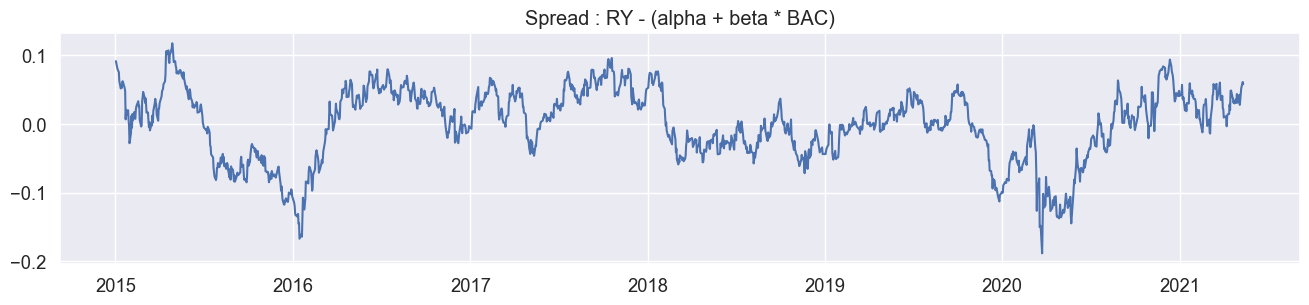

In [23]:
# spread calculation
alpha = results.params[0]
beta = results.params[1]
spread_RY = train_prices_norm['RY'] - (alpha + beta* train_prices_norm['BAC'])

plt.figure(figsize=(16,3))
plt.plot(spread_RY)
plt.title('Spread : RY - (alpha + beta * BAC)')
plt.savefig('Latex Report/Figures/spread_RY.png')
plt.show()

In [24]:
adf_test = adfuller(x = spread_RY, maxlag = 1)                                          
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-3.966373,0.001597,0,1599


$$\Delta e^{RY}_t = \gamma e^{RY}_{t-1} + \delta_1 \Delta e^{RY}_{t-1} + \epsilon_t$$ 

The question now is whether the Cointegrated BAC residual $e^{RY}_t$ is stationary or not. We perform Augmented Dickey-Fuller Test on this Cointegrated RY residual (therefore, referred to as CADF) and conclude that it is stationary since p-value is insignificant and not breaching ADF distribution threshold.

In [25]:
def createTable(df,caption,label,resizeFactor,reportName):
    tmp = df.to_latex(header = True,index = False, float_format = '%0.2f')
    tmp_list = tmp.splitlines()
    tmp = '\n'.join(tmp_list)
    with open('LaTeX Report/Tables/adf_RY_BAC.tex', mode = 'w') as f:
        f.write('\\begin{table}[!ht] \n')
        f.write('\centering \n')
        f.write('\\resizebox{' + resizeFactor + '\\textwidth}{!} { \n')
        f.write(tmp)
        f.write('} \n')
        f.write('\\caption {' + caption + '} \n')
        f.write('\\label {' + caption + '} \n')
        f.write('\\end{table} \n')
        f.write('\\FloatBarrier')
        
createTable(adf_output,'ADF test output on RY Residual/Spread','adf_RY_BAC','0.7','adf_RY_BAC')

### Rgression of Bank of America(BAC) stock on Royal Bank of Canada(RY) stock

In [26]:
model = sm.OLS(endog=train_prices_norm['BAC'],exog = sm.add_constant(train_prices_norm['RY']))           
results = model.fit()     
                            
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    BAC   R-squared:                       0.874
Model:                            OLS   Adj. R-squared:                  0.874
Method:                 Least Squares   F-statistic:                 1.107e+04
Date:                Thu, 11 Jan 2024   Prob (F-statistic):               0.00
Time:                        19:39:14   Log-Likelihood:                 942.21
No. Observations:                1600   AIC:                            -1880.
Df Residuals:                    1598   BIC:                            -1870.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.1742      0.024    -48.212      0.000      -1.222      -1.126
RY             2.4444      0.023    105.210      0.000       2.399       2.490
==============================================================================
Omnibus:                       22.567   Durbin-Watson:                   0.034
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               17.958
Skew:                           0.177   Prob(JB):                     0.000126
Kurtosis:                       2.621   Cond. No.                         14.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [27]:
print(results.summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}    &       BAC        & \textbf{  R-squared:         } &     0.874   \\
\textbf{Model:}            &       OLS        & \textbf{  Adj. R-squared:    } &     0.874   \\
\textbf{Method:}           &  Least Squares   & \textbf{  F-statistic:       } & 1.107e+04   \\
\textbf{Date:}             & Thu, 11 Jan 2024 & \textbf{  Prob (F-statistic):} &     0.00    \\
\textbf{Time:}             &     19:39:20     & \textbf{  Log-Likelihood:    } &    942.21   \\
\textbf{No. Observations:} &        1600      & \textbf{  AIC:               } &    -1880.   \\
\textbf{Df Residuals:}     &        1598      & \textbf{  BIC:               } &    -1870.   \\
\textbf{Df Model:}         &           1      & \textbf{                     } &             \\
\textbf{Covariance Type:}  &    nonrobust     & \textbf{                     } &             \\
\bottomrule
\end{tabular}
\begin{tabular}{lcccccc}
               & \textbf{coef} & \textb

Here, we do linear regression of BAC prices on RY prices.

$$ BAC_t = \mu_e + \beta * RY_t + e_t $$
$\mu_e = -1.1742, \beta = 2.444 $ and residual is as follow 

$$ e_t = BAC_t + 1.1742 - 2.4444 * RY_t $$

where $ \beta_{coint} = [1,-2.444] $

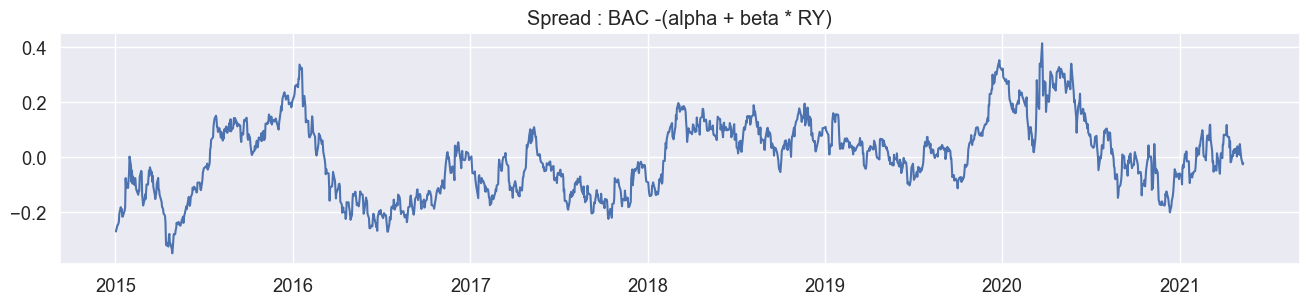

In [29]:
# spread caluclation

alpha = results.params[0]
beta = results.params[1]
spread_BAC = train_prices_norm['BAC'] - (alpha + beta* train_prices_norm['RY'])

plt.figure(figsize=(16,3))
plt.plot(spread_BAC)
plt.title('Spread : BAC -(alpha + beta * RY)')
plt.savefig('Latex Report/Figures/spread_BAC.png')
plt.show()

In [30]:
adf_test = adfuller(x = spread_BAC, maxlag=1)                                          
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-3.972962,0.001559,0,1599


$$\Delta e^{BAC}_t = \gamma e^{BAC}_{t-1} + \delta_1 \Delta e^{BAC}_{t-1} + \epsilon_t$$ 

We perform Augmented Dickey-Fuller Test on this Cointegrated BAC residual $e^{BAC}_t$ and conclude that it is stationary since p-value is insignificant and not breaching ADF distribution threshold.

In [31]:
def createTable(df,caption,label,resizeFactor,reportName):
    tmp = df.to_latex(header = True,index = False, float_format = '%0.2f')
    tmp_list = tmp.splitlines()
    tmp = '\n'.join(tmp_list)
    with open('LaTeX Report/Tables/adf_BAC_RY.tex', mode = 'w') as f:
        f.write('\\begin{table}[!ht] \n')
        f.write('\centering \n')
        f.write('\\resizebox{' + resizeFactor + '\\textwidth}{!} { \n')
        f.write(tmp)
        f.write('} \n')
        f.write('\\caption {' + caption + '} \n')
        f.write('\\label {' + caption + '} \n')
        f.write('\\end{table} \n')
        f.write('\\FloatBarrier')
        
createTable(adf_output,'ADF test output on BAC Residual/Spread','adf_BAC_RY','0.7','adf_BAC_RY')

### 3.4.2 Engle-Granger Procedure Step 2

We will now perform the 2nd step of Engle-Granger procedure which is to estimate the Equilibrium Correction Model(ECM), or error correction equations:

It is a static model that assumes stationary $y_t$ and $x_t$. A dynamic regression model uses several lagged values.

$$ y_t = \alpha y_{t-1} + \beta_0 + \beta_1 x_t + \beta_2 x_{t-1} + \epsilon_t$$

we would like to re-specify the model to equilibrium-correction form

$$ y_t - y_{t-1} =  \alpha y_{t-1} -y_{t-1} + \beta_0 + \beta_1 x_t + \beta_2 x_{t-1} + \epsilon_t$$

$$ \Delta y_t =  -(1-\alpha) y_{t-1}  + \beta_0 + \beta_1 \Delta x_t + (\beta_1 + \beta_2) x_{t-1} + \epsilon_t$$

$$ \Delta y_t=  \beta_1 \Delta x_t -(1-\alpha)\left[y_{t-1} - \frac{\beta_0}{1-\alpha} - \frac{\beta_1 + \beta_2}{1-\alpha} x_{t-1}\right] +  \epsilon_t  $$

$$ \Delta y_t =  \beta_1 \Delta x_t -(1-\alpha)\left[y_{t-1} - a_e -b_e x_{t-1}\right] +  \epsilon_t  $$

$$ \Delta y_t =  \beta_1 \Delta x_t -(1-\alpha)\left[y_{t-1} - a_e -b_e x_{t-1}\right] +  \epsilon_t  $$

$$ \Delta y_t =  \beta_1 \Delta x_t -(1-\alpha) e_{t-1} +  \epsilon_t  $$

where $y_t = a_e + b_e x_t$ is a statis equilibrium model encapsulated within the relationship between non-stationary(integrated) $x_t$ and $y_t$


### Error correction equation ( RY on BAC)

In [32]:
X = pd.DataFrame()
X['ΔPrice_BAC'] = train_prices_norm['BAC'].diff(periods =1).dropna()
X['Lag1_Spread_RY'] = spread_RY.shift(periods = 1).dropna()

Y = pd.DataFrame()
Y['ΔPrice_RY'] = train_prices_norm['RY'].diff(periods = 1).dropna()

model = sm.OLS(endog = Y,exog = X)           
results = model.fit()     

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:              ΔPrice_RY   R-squared (uncentered):                   0.438
Model:                            OLS   Adj. R-squared (uncentered):              0.437
Method:                 Least Squares   F-statistic:                              621.5
Date:                Thu, 11 Jan 2024   Prob (F-statistic):                   2.30e-200
Time:                        19:40:39   Log-Likelihood:                          5146.2
No. Observations:                1599   AIC:                                 -1.029e+04
Df Residuals:                    1597   BIC:                                 -1.028e+04
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
ΔPrice_BAC         0.3091      0.009     35.200      0.000       0.292       0.326
Lag1_Spread_RY    -0.0176      0.005     -3.729      0.000      -0.027      -0.008
==============================================================================
Omnibus:                      250.526   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2055.379
Skew:                          -0.473   Prob(JB):                         0.00
Kurtosis:                       8.473   Cond. No.                         1.86
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [36]:
print(results.summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}    &    ΔPrice\_RY    & \textbf{  R-squared (uncentered):}      &     0.438   \\
\textbf{Model:}            &       OLS        & \textbf{  Adj. R-squared (uncentered):} &     0.437   \\
\textbf{Method:}           &  Least Squares   & \textbf{  F-statistic:       }          &     621.5   \\
\textbf{Date:}             & Thu, 11 Jan 2024 & \textbf{  Prob (F-statistic):}          & 2.30e-200   \\
\textbf{Time:}             &     19:42:12     & \textbf{  Log-Likelihood:    }          &    5146.2   \\
\textbf{No. Observations:} &        1599      & \textbf{  AIC:               }          & -1.029e+04  \\
\textbf{Df Residuals:}     &        1597      & \textbf{  BIC:               }          & -1.028e+04  \\
\textbf{Df Model:}         &           2      & \textbf{                     }          &             \\
\textbf{Covariance Type:}  &    nonrobust     & \textbf{                     }          &             \\
\bottomru

**Error correction equation for RY on BAC**

$$\Delta P^{RY}_t = \phi \Delta P^{BAC}_{t} - (1-\alpha) \text{Coint_RYBAC}_{t-1} + \epsilon_t$$  

Here we check significance of  −(1−α) term that ensures the correction the long run equilibrium.

In error correction equation the  p-value is evaluated agaist t-distribution as is common for regression. We will reject  H0
(that a regression coefficient is zero) because the corresponding  p-value is less than 5%. Above table indicates regression coefficient is siginificantly different from zero.

We also observe that speed of correction -(1- $\alpha$) = -0.0176 is very small, but is significant for cointegration to exist

### 3.4.2 Error correction equations(BAC on RY)

In [37]:
X = pd.DataFrame()
X['ΔPrice_RY'] = train_prices_norm['RY'].diff(periods =1).dropna()
X['Lag1_Spread_BAC'] = spread_BAC.shift(periods = 1).dropna()

Y = pd.DataFrame()
Y['ΔPrice_BAC'] = train_prices_norm['BAC'].diff(periods = 1).dropna()

model = sm.OLS(endog = Y,exog = X)           
results = model.fit()     

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:             ΔPrice_BAC   R-squared (uncentered):                   0.438
Model:                            OLS   Adj. R-squared (uncentered):              0.437
Method:                 Least Squares   F-statistic:                              622.4
Date:                Thu, 11 Jan 2024   Prob (F-statistic):                   1.38e-200
Time:                        19:42:18   Log-Likelihood:                          3930.9
No. Observations:                1599   AIC:                                     -7858.
Df Residuals:                    1597   BIC:                                     -7847.
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
ΔPrice_RY           1.4124      0.040     35.179      0.000       1.334       1.491
Lag1_Spread_BAC    -0.0149      0.004     -3.864      0.000      -0.022      -0.007
==============================================================================
Omnibus:                      208.329   Durbin-Watson:                   2.072
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1516.192
Skew:                           0.364   Prob(JB):                         0.00
Kurtosis:                       7.715   Cond. No.                         10.4
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [38]:
print(results.summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}    &   ΔPrice\_BAC    & \textbf{  R-squared (uncentered):}      &     0.438   \\
\textbf{Model:}            &       OLS        & \textbf{  Adj. R-squared (uncentered):} &     0.437   \\
\textbf{Method:}           &  Least Squares   & \textbf{  F-statistic:       }          &     622.4   \\
\textbf{Date:}             & Thu, 11 Jan 2024 & \textbf{  Prob (F-statistic):}          & 1.38e-200   \\
\textbf{Time:}             &     19:42:22     & \textbf{  Log-Likelihood:    }          &    3930.9   \\
\textbf{No. Observations:} &        1599      & \textbf{  AIC:               }          &    -7858.   \\
\textbf{Df Residuals:}     &        1597      & \textbf{  BIC:               }          &    -7847.   \\
\textbf{Df Model:}         &           2      & \textbf{                     }          &             \\
\textbf{Covariance Type:}  &    nonrobust     & \textbf{                     }          &             \\
\bottomru

**Error correction equation for BAC on RY**

$$\Delta P^{BAC}_t = \phi \Delta P^{RY}_{t} - (1-\alpha) \text{Coint_BACRY}_{t-1} + \epsilon_t$$  

Here we check significance of  −(1−α) term that ensures the correction in long run equilibrium.

In error correction equation the  p-value is evaluated agaist t-distribution as is common for regression. We will reject  H0
(that a regression coefficient is zero) because the corresponding  p-value is less than 5%. Above table indicates regression coefficient is siginificantly different from zero.

We also observe that speed of correction -(1- $\alpha$) = -0.0149 is very small, but is significant for cointegration to exist

**At the end, we select later case - Error correction equation for BAC on RY, although we do not see much improvement of one over another.**

### 3.5 OU Process fitting

The strategy trades the spread from the long/short portfolio(weights given  $\beta_{Coint}$).
For a mean-reversion arbitrage, we require the following items of information:
- Weights for a set of instruments $\beta_{Coint}$ to construct a spread.
- Speed of mean-reversion in the spread $\theta$ to evaluate the feasibility of a trade.
- Entry and exit levels together with the equilibrium level $\mu_e$, around which mean-reversion occurs. Fitting a spread to the Ornstein-Uhlenbeck process allows calculating the bounds as $$\sigma_{eq} \approx \frac{\sigma_{OU}}{\sqrt{2\theta}}$$

Eq (2) shows that the spread $e_t = \beta Y_t $ is an AR(1) process which makes it technically possible to perform fitting to the Ornstein-Uhlenbeck process and evaluate the speed of mean-reversion $\theta$ : the higher the $\theta$ the more stronger and less fractionated the cointegrated relationship is. That is possible to establish without conducting formal econometric tests for cointegration. Other fitted parameters, the equilibrium level $\mu_e$ and $\sigma_{eq}$ offer to calculate z-score given that $e_{t,\tau \to \infty} \thicksim N(\mu_e,\sigma^2_{eq} $ eq).
OU fitting recipe uses the AR(1) model and is surprisingly simple as Eq (3).
Parameters equilibrium level $\mu_e$, speed of mean reversion $\theta$ and diffudion $\sigma_{eq}$ are calculatedare given as follows -

$$ \theta = - \frac{ln B}{\tau}, \mu_e = \frac{C}{1-B}, \sigma_{eq} = \sqrt{\frac{SSE/T}{1- e^{-2\theta\tau}}}$$

Comparison of the OU SDE solution to Equilibrium Correction mechanism Eq (7) gives an insightful representation, where all parameters fall in correct places with identifiable roles. In particular, the speed of adjustment towards the equilibrium is proportional to the autocorrelation of the OU process $\alpha \propto e^{-\theta\tau}$ , which is mean-reverting.

In order to give an indication of time required to generate the P&L, the reversion speed can be presented as a global half-life: the time between the equilibrium situations of spread $e_t$ being at $\mu_e$.

$$\tilde{\tau} \propto \frac{ln 2}{\theta}$$

Mean-reversion begins with $\theta$ > 0. The higher the theta the shorter half-life of reversion to the mean, and the better the quality of mean-reversion becomes

In [41]:
model = AutoReg(spread_BAC,lags = 1)                       
fitted_model = model.fit()                                
b =  fitted_model.params[1]
c = fitted_model.params[0]

fitted_model.summary() 

<class 'statsmodels.iolib.summary.Summary'>
"""
                            AutoReg Model Results                             
==============================================================================
Dep. Variable:                      y   No. Observations:                 1600
Model:                     AutoReg(1)   Log Likelihood                3654.105
Method:               Conditional MLE   S.D. of innovations              0.025
Date:                Thu, 11 Jan 2024   AIC                          -7302.210
Time:                        19:42:55   BIC                          -7286.079
Sample:                             1   HQIC                         -7296.220
                                 1600                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.001      0.253      0.800      -0.001       0.001
y.L1           0.9818      0.005    214.186      0.000       0.973       0.991
                                    Roots                                    
=============================================================================
                  Real          Imaginary           Modulus         Frequency
-----------------------------------------------------------------------------
AR.1            1.0186           +0.0000j            1.0186            0.0000
-----------------------------------------------------------------------------
"""

In [42]:
print(fitted_model.summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:} &             y             & \textbf{  No. Observations:  } &            1600            \\
\textbf{Model:}         &         AutoReg(1)        & \textbf{  Log Likelihood     } &          3654.105          \\
\textbf{Method:}        &      Conditional MLE      & \textbf{  S.D. of innovations} &           0.025            \\
\textbf{Date:}          &      Thu, 11 Jan 2024     & \textbf{  AIC                } &         -7302.210          \\
\textbf{Time:}          &          19:43:08         & \textbf{  BIC                } &         -7286.079          \\
\textbf{Sample:}        &             1             & \textbf{  HQIC               } &         -7296.220          \\
\textbf{}               &            1600           & \textbf{                     } &                            \\
\bottomrule
\end{tabular}
\begin{tabular}{lcccccc}
               & \textbf{coef} & \textbf{std err} & \textbf{z} & \textbf{P$> |$z$|$}

In [43]:
tau = 1/252
theta = -np.log(b)/tau
half_life = np.log(2)/theta
SSE = np.sum(fitted_model.resid**2)
T = len(spread_BAC)-1
mu_eq = c/(1-b)
sigma_eq = np.sqrt((SSE/T)/(1-np.exp(-2*theta*tau)))

As we can see half-life is 36.6 days.
The speed of mean-reversion, in this case, is not particularly fast so we might not expect that many trades when implementing the strategy that trades the spread by constructing a long/short portfolio.


In [44]:
columns = ['B','C','mu_eq','sigma_eq']
ou_fitting = pd.DataFrame([[b,c,mu_eq,sigma_eq]],columns = columns)
dfstyler = ou_fitting.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

B,C,mu_eq,sigma_eq
0.981778,0.000156,0.008547,0.129558


In [45]:
def createTable(df,caption,label,resizeFactor,reportName):
    tmp = df.to_latex(header = True,index = False, float_format = '%0.2f')
    tmp_list = tmp.splitlines()
    tmp = '\n'.join(tmp_list)
    with open('LaTeX Report/Tables/ou_fitting.tex', mode = 'w') as f:
        f.write('\\begin{table}[!ht] \n')
        f.write('\centering \n')
        f.write('\\resizebox{' + resizeFactor + '\\textwidth}{!} { \n')
        f.write(tmp)
        f.write('} \n')
        f.write('\\caption {' + caption + '} \n')
        f.write('\\label {' + caption + '} \n')
        f.write('\\end{table} \n')
        f.write('\\FloatBarrier')
        
createTable(ou_fitting,'OU Fitting Parameters on BAC Residual/Spread','ou_fitting','0.7','ou_fitting')

# 4 Trading Strategy

### 4.1 Strategy formulation & Assumptions

(1) At the end of each trading day, algorithm checks spread(residual) of BAC stock and computes trading signals based on $ \mu_{eq}, z \, and \, \sigma_{eq} $ values.

(2) For long/short entry signals received at the end of day t1, accumlation of returns will start from subsequent day (t+1). Similarly, for long/short exit signal received at the end of day t2, acculation of returns will end on this day (t2).

(3) Based on the optimization of P&L, we optimal Z value and approach is as follows:
 - To take long position (1 unit long position of BAC stock and beta units short position of RY stock) when spread $e_t$ crosses upper bound $\mu_{eq} + Z_{optimnal} \sigma_{eq} $ from below, and there is no position. When spread $e_t$ reverts to value $\mu_{eq}$ then exit the position.
 - Similarly, to take short position when spread $e_t$ crosses lower bound $\mu_{eq} - Z_{optimnal} \sigma_{eq} $ from above, and there is no position. When spread $e_t$ reverts to value $\mu_{eq}$ then exit the position.
 
(4) This is an example of 'Buy & Hold' strategy, means we take either long or short position on spread based on entry signal and hold it until we get exit signal for the same. **There is no rule for accumlation of position**

(5) we calculate gross and net returns based on user-specific fee percent parameter i.e. whenever we take new position or exit exisitng position, fee percent is deducted from gross returns to arrive at net returns.

In [47]:
def trading_strategy(df_prices_norm,z_value,mu_eq,sigma_eq):

    # read parameters
    prices_norm = df_prices_norm
    z = z_value
    mu = mu_eq
    sigma = sigma_eq
    
    # calculate spread/residual for regression of BAC on RY
    model = sm.OLS(endog=prices_norm['BAC'],exog = sm.add_constant(prices_norm['RY']))           
    results = model.fit()     
    spread_BAC = results.resid
    beta = results.params[1]     
    
    df_signal = pd.DataFrame()
    signal_entry = mu + z * sigma
    signal_exit = mu

    df_signal['BAC'] = prices_norm['BAC']
    df_signal['RY'] = prices_norm['RY']
    df_signal['SP500'] = prices_norm['^GSPC']
    df_signal['signal_score'] = spread_BAC

    # generating trading signals
    df_signal['signal_short_entry'] = (spread_BAC > signal_entry) & (spread_BAC.shift(1) < signal_entry) 
    df_signal['signal_short_exit'] = (spread_BAC < signal_exit) & (spread_BAC.shift(1) > signal_exit) 
    df_signal['signal_long_entry'] = (spread_BAC < -signal_entry) & (spread_BAC.shift(1) > -signal_entry) 
    df_signal['signal_long_exit'] = (spread_BAC > -signal_exit) & (spread_BAC.shift(1) < -signal_exit) 
    
    # computation of trading strategy return along with benchmark(S&P 500) return
    signal = None
    counter = -1
    strategy_result = []
    indicator = 0

    for time, signal_stock in  df_signal.iterrows():
        counter += 1
        BAC, RY, SP500 , signal_score,signal_short_entry, signal_short_exit, signal_long_entry, signal_long_exit = signal_stock

        if counter == 0:
            return_BAC_pos = 0
            return_RY_pos = 0
            return_SP500 = 0
            strategy_result.append([time, signal, return_BAC_pos, return_RY_pos, return_SP500])

        else:      
            if signal == None:
                return_BAC_pos = 0
                return_RY_pos = 0
                return_SP500 = (df_signal['SP500'][counter] / df_signal['SP500'][counter-1]) - 1
                strategy_result.append([time, signal, return_BAC_pos,return_RY_pos,return_SP500])

                if signal_short_entry == True:
                    signal = 'short'
                elif signal_long_entry == True:
                    signal = 'long'


            elif signal == 'long':
                return_BAC_pos = (df_signal['BAC'][counter] / df_signal['BAC'][counter-1]) - 1
                return_RY_pos = (df_signal['RY'][counter] / df_signal['RY'][counter-1]) - 1
                return_SP500 = (df_signal['SP500'][counter] / df_signal['SP500'][counter-1]) - 1
                strategy_result.append([time,signal, return_BAC_pos, -return_RY_pos, return_SP500])

                if signal_long_exit == True:
                    signal = None


            elif signal == 'short':
                return_BAC_pos = (df_signal['BAC'][counter] / df_signal['BAC'][counter-1]) - 1
                return_RY_pos = (df_signal['RY'][counter] / df_signal['RY'][counter-1]) - 1
                return_SP500 = (df_signal['SP500'][counter] / df_signal['SP500'][counter-1]) - 1
                strategy_result.append([time, signal, -return_BAC_pos, return_RY_pos, return_SP500])

                if signal_short_exit == True:
                    signal = None
                    
        #old_signal = signal
                    
    # collection of P&L data in dataframe
    df_strategy = pd.DataFrame(strategy_result)
    df_strategy.columns = ['Date', 'Signal','Position BAC Return', 'Position RY Return', 'SP500 Return']
    df_strategy['n_Trades'] =  np.cumsum(abs(pd.Series(np.where(df_strategy['Signal'].isin(['long','short']),1,0)).diff()))
    df_strategy['BAC PL'] = 1* np.cumprod(df_strategy['Position BAC Return'] + 1)
    df_strategy['RY PL'] =  beta * np.cumprod(df_strategy['Position RY Return'] + 1)
    df_strategy['SP500 PL'] = np.cumprod(df_strategy['SP500 Return'] + 1)
    df_strategy['Strategy PL'] = (df_strategy['BAC PL']  + df_strategy['RY PL'])
    df_strategy['Strategy PL'] = df_strategy['Strategy PL']/df_strategy['Strategy PL'][0]
    df_strategy['Strategy Return'] = df_strategy['Strategy PL'].pct_change(periods=1)
    df_strategy['Strategy Return'].iloc[0] = 0
    df_strategy.set_index('Date',drop = True, inplace=True)    

    return df_strategy

In [58]:
def trading_strategy_1(df_prices_norm,z_value,mu_eq,sigma_eq,fee_pct):

    # read parameters
    prices_norm = df_prices_norm
    z = z_value
    mu = mu_eq
    sigma = sigma_eq
    fee_pct = fee_pct
    
    # calculate spread/residual for regression of BAC on RY
    model = sm.OLS(endog=prices_norm['BAC'],exog = sm.add_constant(prices_norm['RY']))           
    results = model.fit()     
    spread_BAC = results.resid
    beta = results.params[1]     
    
    df_signal = pd.DataFrame()
    signal_entry = mu + z * sigma
    signal_exit = mu
     
    df_signal['BAC'] = prices_norm['BAC']
    df_signal['RY'] = prices_norm['RY']
    df_signal['SP500'] = prices_norm['^GSPC']  
    df_signal['signal_score'] = spread_BAC 

    # generating trading signals
    df_signal['signal_short_entry'] = (spread_BAC > signal_entry) & (spread_BAC.shift(1) < signal_entry) 
    df_signal['signal_short_exit'] = (spread_BAC < signal_exit) & (spread_BAC.shift(1) > signal_exit) 
    df_signal['signal_long_entry'] = (spread_BAC < -signal_entry) & (spread_BAC.shift(1) > -signal_entry) 
    df_signal['signal_long_exit'] = (spread_BAC > -signal_exit) & (spread_BAC.shift(1) < -signal_exit) 
    
    # computation of trading strategy return along with benchmark(S&P 500) return
    position = 0
    old_position = 0
    counter = -1
    strategy_result = []
    indicator = 0

    for time, signal_stock in  df_signal.iterrows():
        
        counter += 1
        BAC, RY, SP500 , signal_score,signal_short_entry, signal_short_exit, signal_long_entry, signal_long_exit = signal_stock
        
        # for day 1 seting gross returns, fee, net returns & S&P 500 return as zero
        if counter == 0:
            ret_BAC_gross = 0
            ret_RY_gross = 0          
            fee = 0
            ret_BAC_net= 0 
            ret_RY_net= 0
            ret_SP500 = 0
            strategy_result.append([time, position, old_position,ret_BAC_gross, ret_RY_gross, fee, ret_BAC_net, ret_RY_net,ret_SP500])

        else:      
            if position == 0:
                ret_BAC_gross = 0
                ret_RY_gross = 0        
                fee = fee_pct*abs(position - old_position)
                ret_BAC_net= ret_BAC_gross - fee
                ret_RY_net= ret_RY_gross - fee
                ret_SP500 = (df_signal['SP500'][counter] / df_signal['SP500'][counter-1]) - 1
                strategy_result.append([time, position, old_position, ret_BAC_gross, ret_RY_gross, fee, ret_BAC_net, ret_RY_net,ret_SP500])

                old_position = position
                
                if signal_short_entry == True:
                    position = -1
                elif signal_long_entry == True:
                    position = 1


            elif position == 1:
                ret_BAC_gross = (df_signal['BAC'][counter] / df_signal['BAC'][counter-1]) - 1
                ret_RY_gross = (df_signal['RY'][counter] / df_signal['RY'][counter-1]) - 1               
                fee = fee_pct*abs(position - old_position)
                ret_BAC_net= ret_BAC_gross - fee
                ret_RY_net= ret_RY_gross - fee
                ret_SP500 = (df_signal['SP500'][counter] / df_signal['SP500'][counter-1]) - 1
                strategy_result.append([time, position, old_position,ret_BAC_gross, -ret_RY_gross, fee, ret_BAC_net, -ret_RY_net,ret_SP500])

                old_position = position
                
                if signal_long_exit == True:
                    position = 0


            elif position == -1:
                ret_BAC_gross = (df_signal['BAC'][counter] / df_signal['BAC'][counter-1]) - 1
                ret_RY_gross = (df_signal['RY'][counter] / df_signal['RY'][counter-1]) - 1
                fee = fee_pct*abs(position - old_position)
                ret_BAC_net= ret_BAC_gross - fee
                ret_RY_net= ret_RY_gross - fee
                ret_SP500 = (df_signal['SP500'][counter] / df_signal['SP500'][counter-1]) - 1
                strategy_result.append([time, position,old_position,-ret_BAC_gross, ret_RY_gross, fee, -ret_BAC_net, ret_RY_net,ret_SP500])

                old_position = position
                
                if signal_short_exit == True:
                    position = 0
                    
              
    # collection of P&L data in dataframe
    df_strategy = pd.DataFrame(strategy_result)
    df_strategy.columns = ['Date', 'Position','Old Position','Gross BAC Return', 'Gross RY Return','Fee','Net BAC Return', 'Net RY Return' ,'SP500 Return']
    #df_strategy['n_Trades'] =  np.cumsum(abs(pd.Series(np.where(df_strategy['Signal'].isin(['long','short']),1,0)).diff()))
    df_strategy['n_Trades'] =  np.cumsum(abs(df_strategy['Position'].diff()))
    df_strategy['Gross BAC PL'] = 1* np.cumprod(df_strategy['Gross BAC Return'] + 1)
    df_strategy['Gross RY PL'] =  beta * np.cumprod(df_strategy['Gross RY Return'] + 1)
    df_strategy['Net BAC PL'] = 1* np.cumprod(df_strategy['Net BAC Return'] + 1)
    df_strategy['Net RY PL'] =  beta * np.cumprod(df_strategy['Net RY Return'] + 1)   
    df_strategy['SP500 PL'] = np.cumprod(df_strategy['SP500 Return'] + 1)
    df_strategy['Gross Strategy PL'] = (df_strategy['Gross BAC PL']  + df_strategy['Gross RY PL'])
    df_strategy['Gross Strategy PL'] = df_strategy['Gross Strategy PL']/df_strategy['Gross Strategy PL'][0]
    df_strategy['Net Strategy PL'] = (df_strategy['Net BAC PL']  + df_strategy['Net RY PL'])
    df_strategy['Net Strategy PL'] = df_strategy['Net Strategy PL']/df_strategy['Net Strategy PL'][0]    
    df_strategy['Gross Strategy Return'] = df_strategy['Gross Strategy PL'].pct_change(periods=1)
    df_strategy['Gross Strategy Return'].iloc[0] = 0
    df_strategy['Net Strategy Return'] = df_strategy['Net Strategy PL'].pct_change(periods=1)
    df_strategy['Net Strategy Return'].iloc[0] = 0    
    df_strategy.set_index('Date',drop = True, inplace=True)    

    return df_strategy

### 4.2 Optimization of Z  value based on Cumulative P&L 

In [48]:
z_values = [0.4,0.5,0.6,0.7,0.8,0.9,1,1.1,1.2,1.3,1.4,1.5,1.6]
n_trades = [trading_strategy(train_prices_norm,z,mu_eq,sigma_eq)['n_Trades'][-1] for z in z_values ]
strategy_pl = [trading_strategy(train_prices_norm,z,mu_eq,sigma_eq)['Strategy PL'][-1] for z in z_values]

df_zValues = pd.DataFrame({'n_Trades':n_trades,'Strategy PL':strategy_pl, 'z_Values':z_values})
df_zValues.set_index('z_Values', drop= True, inplace = True)
z_optimal = df_zValues['Strategy PL'].idxmax()  
df_zValues

,n_Trades,Strategy PL
z_Values,,
0.4,58.0,2.340503
0.5,50.0,2.489257
0.6,48.0,2.346057
0.7,42.0,2.632363
0.8,36.0,2.623089
0.9,26.0,2.143504
1.0,26.0,2.108517
1.1,20.0,1.888270
1.2,18.0,1.870907


Based on Strategy cumulative P&L, we get optimal Z value as 0.7 which has number of trades as 42 including both entry and exit sides.

In [49]:
def createTable(df,caption,label,resizeFactor,reportName):
    tmp = df.to_latex(header = True,index = False, float_format = '%0.2f')
    tmp_list = tmp.splitlines()
    tmp = '\n'.join(tmp_list)
    with open('LaTeX Report/Tables/ou_fitting.tex', mode = 'w') as f:
        f.write('\\begin{table}[!ht] \n')
        f.write('\centering \n')
        f.write('\\resizebox{' + resizeFactor + '\\textwidth}{!} { \n')
        f.write(tmp)
        f.write('} \n')
        f.write('\\caption {' + caption + '} \n')
        f.write('\\label {' + caption + '} \n')
        f.write('\\end{table} \n')
        f.write('\\FloatBarrier')
        
createTable(ou_fitting,'OU Fitting Parameters on BAC Residual/Spread','ou_fitting','0.7','ou_fitting')

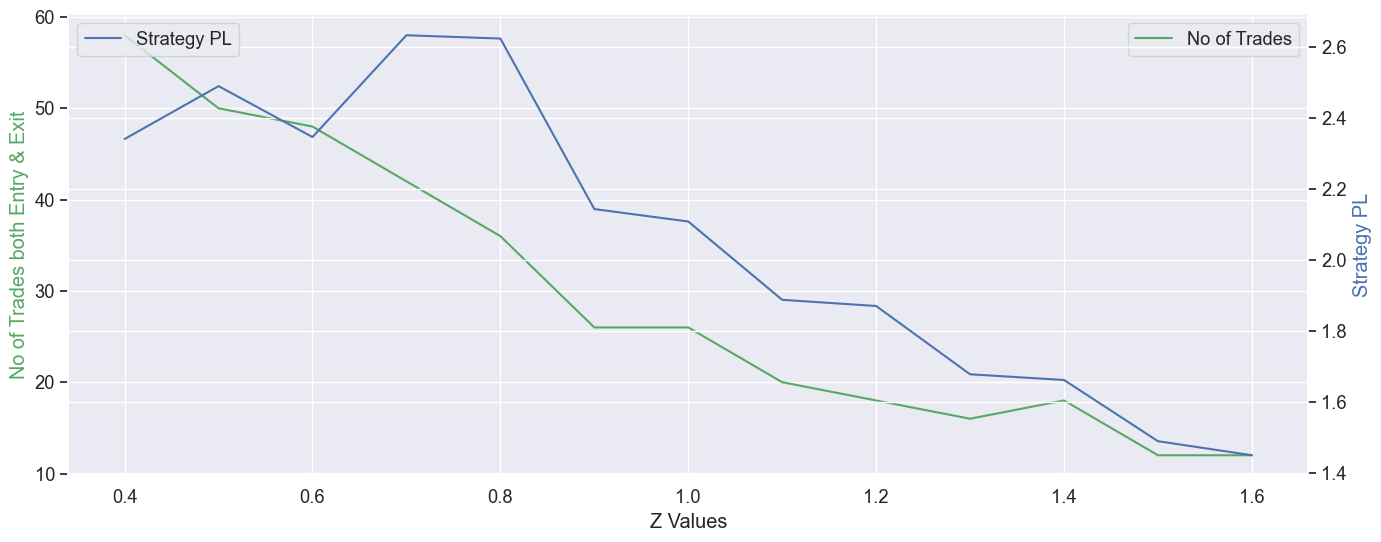

In [52]:
fig, ax1 = plt.subplots(figsize =(16,6))

ax2 = ax1.twinx()
ax1.plot(df_zValues.index, df_zValues['n_Trades'], color = 'g',label = 'No of Trades')
ax2.plot(df_zValues.index, df_zValues['Strategy PL'], color = 'b',label = 'Strategy PL')
ax1.set_xlabel('Z Values')
ax1.set_ylabel('No of Trades both Entry & Exit', color = 'g')
ax1.legend(loc='upper right')
ax2.set_ylabel('Strategy PL', color = 'b')
ax2.legend(loc='upper left')
plt.savefig('Latex Report/Figures/z_values.png')
plt.show()


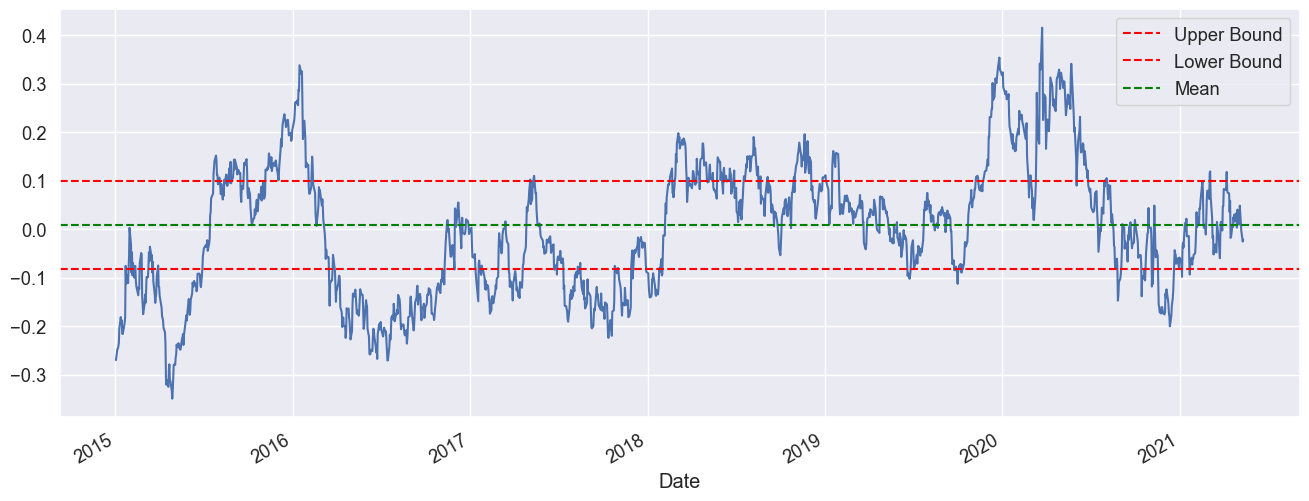

In [51]:
spread_BAC.plot(figsize = (16,6))
plt.axhline(y = mu_eq + z_optimal * sigma_eq,label='Upper Bound', color = 'red',linestyle ='--')   
plt.axhline(y = mu_eq - z_optimal * sigma_eq,label='Lower Bound', color = 'red',linestyle ='--') 
plt.axhline(y = mu_eq ,label='Mean', color = 'green',linestyle ='--') 
plt.legend()
plt.savefig('Latex Report/Figures/spread_bound.png')
plt.show()

Above plot shows upper bound as 0.7085 and lower bound as -0.69145 with eqilibrium level as 0.0085 for trading signals.

### 3.3 Strategy P&L and comparison with Benchmark P&L

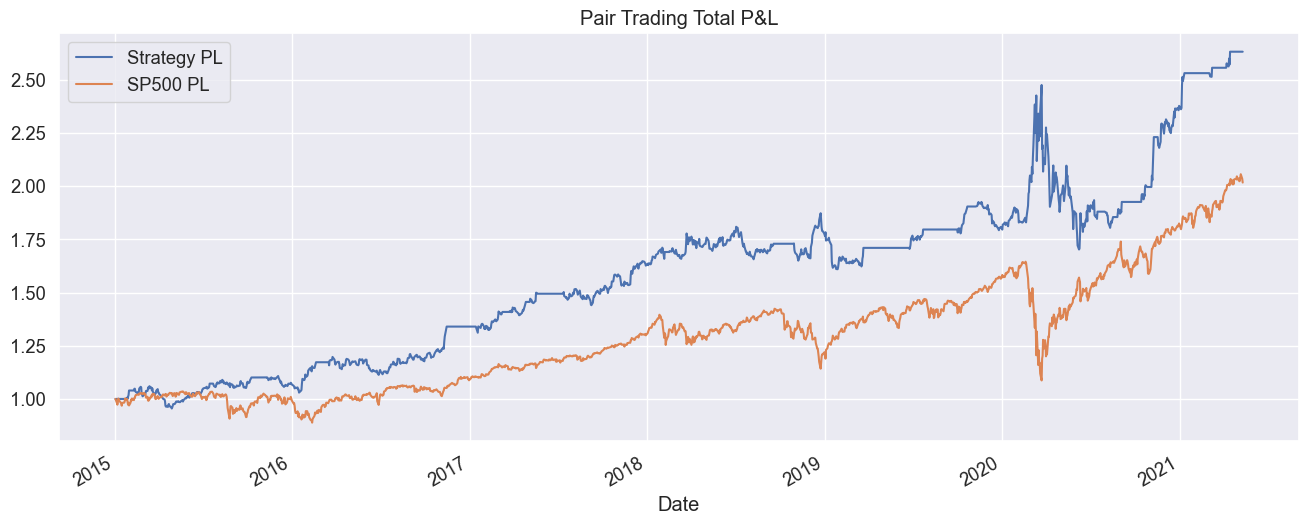

In [57]:
df_strategy = trading_strategy(train_prices_norm,z_optimal,mu_eq,sigma_eq)
df_strategy[['Strategy PL','SP500 PL']].plot(figsize = (16,6))
plt.title('Pair Trading Total P&L')
plt.savefig('Latex Report/Figures/strategy_pnl.png')
plt.show()

In [ ]:
df_strategy = trading_strategy_1(train_prices_norm,z_optimal,mu_eq,sigma_eq,0.01)
df_strategy[['Gross Strategy PL','Net Strategy PL','SP500 PL']].plot(figsize = (16,6))
plt.title('Pair Trading Total P&L')
plt.show()

In [ ]:
df_backtest.to_clipboard()

**Straetgy P&L Results & Limitations**

(1) Pairs trading strategy can help to get good returns regardless of the conditions of the market. Hence, in the pair trading strategy can earn good returns it leverages on the opportunity when one asset is undervalued/overvalued wrt other asset in pair.

(2) Here, we observe that strategy P&L is delivering ~ 260% returns in 6 years period and it is exceeding market returns ~ 200%. Hence we conclude that straetgy is working well and can be suitable for real-life implementation.

(3) We also observe that, startegy is performing better tham benchamrk index particularly in falling market conditions i.e startegy returns are positive in COVID periods.

(4) We did not include concept of stop-loss in trading startegy design. However, due to risk management policies/governance, smetimes it is mandatiry to keep stop-loss limits for trading positions to avoid heavy losses i.e. unexpectedly, spread takes much more time to revert to equilibrium level.







# 4. Backtesting of Trading Strategy

Now that we have constructed our spread appropriately and have an idea of how we will go about making trades, it is time to conduct some out of sample testing. Our whole model is based on the premise that these securities are cointegrated, but we built it on information from a certain time period. If we actually want to implement this model, we need to conduct an out of sample test to confirm that the principles of our model are still valid going forward.
Historical results do not guarantee future results so this is a sanity check to see if the work we have done holds strong.

For systematic backtesting of trading starategy, we use test dataset which contains stock prices data from May-2021 to Dec-2022.

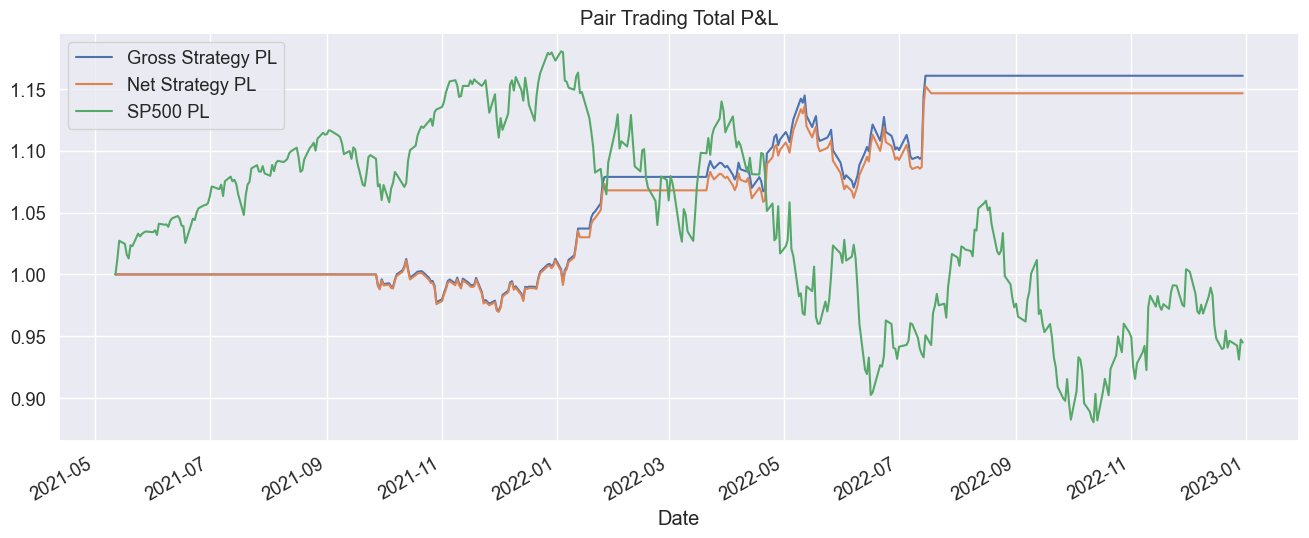

In [59]:
df_backtest = trading_strategy_1(test_prices_norm,z_optimal,mu_eq,sigma_eq,0.005)
df_backtest[['Gross Strategy PL','Net Strategy PL','SP500 PL']].plot(figsize = (16,6))
plt.title('Pair Trading Total P&L')
plt.savefig('Latex Report/Figures/backtest_pnl.png')
plt.show()

**Backtesting P&L Results & Areas of Improvement**

(1) Here, we observe that backtesitng P&L is delivering ~ 15% returns in 1.5 years period and it is exceeding negative market returns in the same period. Hence we conclude that out of sample testing of trading strategy is still delivering excellent results. 

(2) For the pairs trading strategy cointegration test, we only used a handful of stocks. Naturally (and in practice) it would be more effective to use clusters within an industry.

(3) **Dealing with overfitting** -Anything related to data analysis and training models has much to do with the problem of overfitting. There are many different ways to deal with overfitting like validation, such as Kalman filters, and other statistical methods.

(4) Cointegrated relationship supposed to persist and $β_{Coint}$ should stay the same. However, it is not always the case and sometimes,cointegrated relationships require regular re-estimation- Kalman filter or particle filter adaptive estimation can be useful here.

### 4.2 Portfolio Risk-Return Analytics

Start date,2021-05-12
End date,2022-12-30
Total months,19
,Backtest
Annual return,8.7%
Cumulative returns,14.7%
Annual volatility,7.4%
Sharpe ratio,1.16
Calmar ratio,1.33
Stability,0.87
Max drawdown,-6.5%


Worst drawdown periods,Net drawdown in %,Peak date,Valley date,Recovery date,Duration
0,6.54,2022-05-12,2022-06-07,2022-07-14,46
1,4.11,2021-10-13,2021-12-01,2021-12-31,58
2,2.24,2022-03-23,2022-04-20,2022-04-22,23
3,1.96,2021-12-31,2022-01-04,2022-01-10,7
4,1.21,2021-09-27,2021-09-29,2021-10-11,11


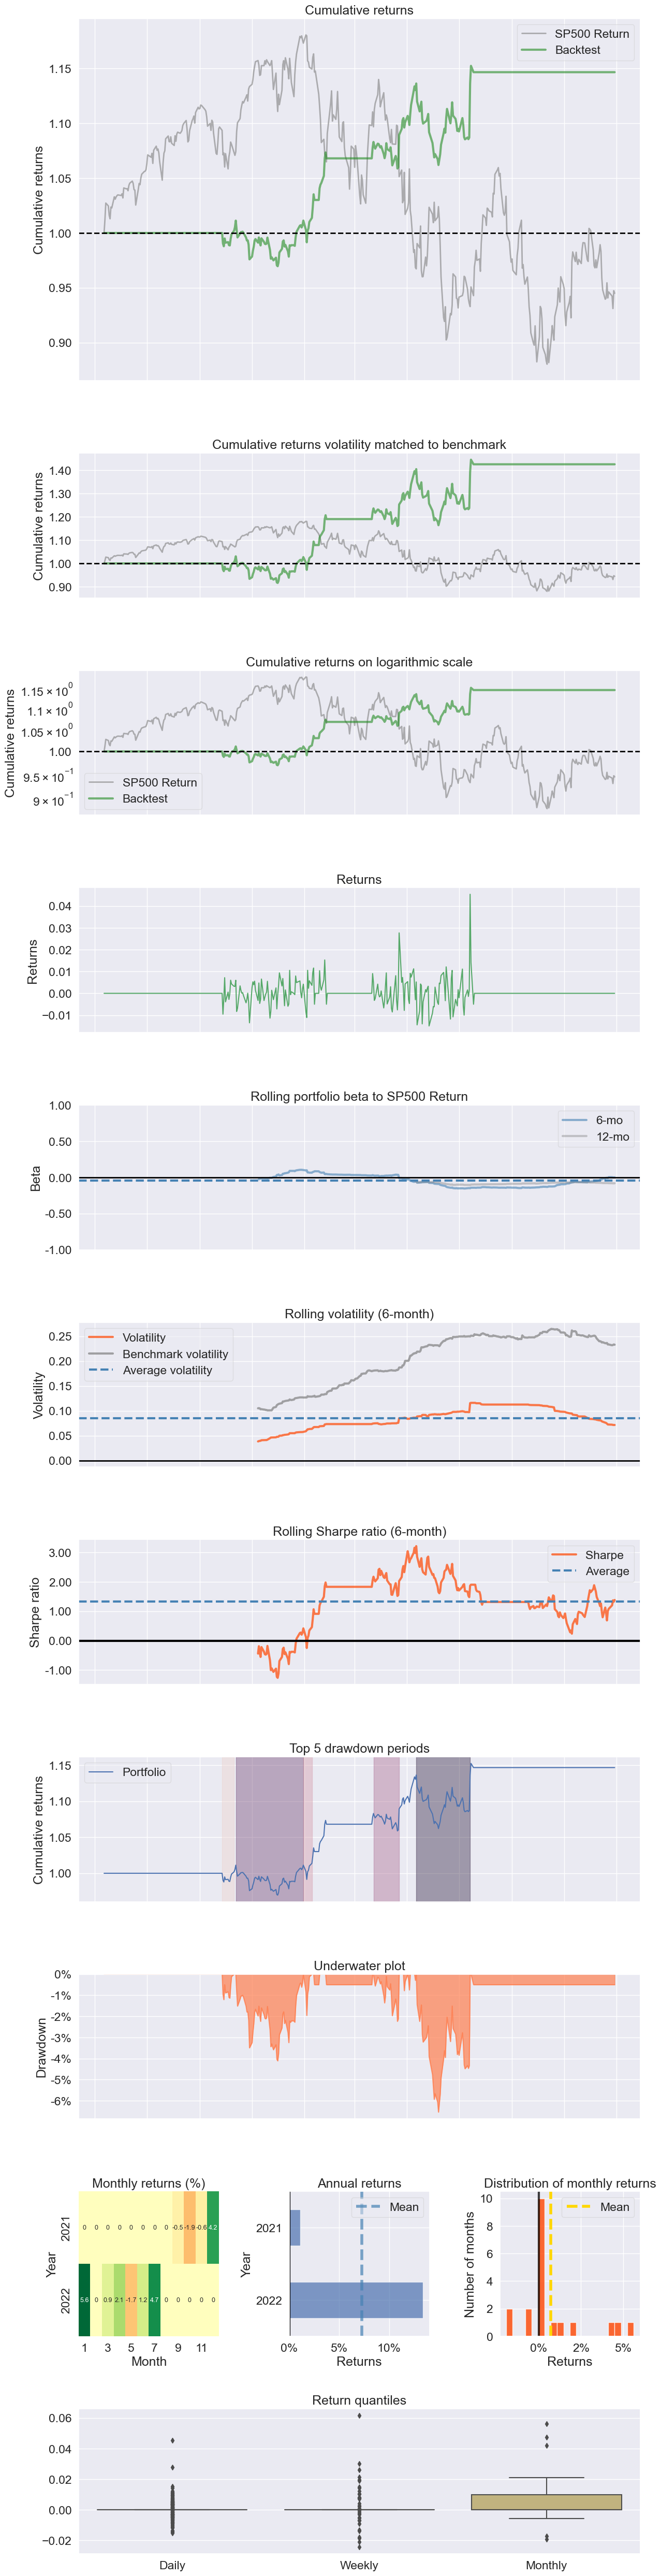

In [64]:
a = pf.create_returns_tear_sheet(df_backtest['Net Strategy Return'], benchmark_rets = df_backtest['SP500 Return'],return_fig=True)
a.savefig('Latex Report/Figures/pyfolio.png')

# Appendix

### A.1 Ornstein-Uhlenbeck Process(Quality of Mean-Reversion)

We use the process in order to model the residual of cointegrating relationship (vector error term) $e_t = \beta_{coint} Y_t$, given its statistical properties of being stationary AR(1) process with frequent mean reversion around $\mu_e$ .Its SDE gives
a continuous representation of an autoregressive process with the mean-reviersion $\theta$ and 
and diffusion $\sigma_{OU} $.

\begin{equation} \label{eq:eq1} de_t = -\theta(e_t - \mu_e) dt + \sigma_{OU} dX_t \end{equation} 

the regression-like solution in continuous time t + $\tau$ 

\begin{equation} \label{eq:eq2} e_{t+\tau} = (1 -e^{-\theta \tau}) \mu_e + e^{-\theta \tau} e_t + \epsilon_{t,\tau}\end{equation} 

OU SDE solution offers two terms: reversive and autoregressive

Autoregressive equivalent for a small time period $\tau$ is

\begin{equation} \label{eq:eq3} e_{t+\tau} = C + B e_t + \epsilon_{t,\tau} \end{equation}

Once AR(1) is estimated, we can solve for equilibrium level $\mu_e$  and speed of mean reversion $\theta$

$$ \theta = - \frac{ln B}{\tau}, \mu_e = \frac{C}{1-B}$$ 

The following comparison shows that the Ornstein-Uhlenbeck process fit matches the features of equilibrium-correction term, which is commonly present in econometric cointegration models.
\begin{equation} \label{eq:eq4} e_{t+\tau} = (1 -e^{-\theta \tau}) \mu_e + e^{-\Theta \tau} e_t \end{equation} 

\begin{equation} \label{eq:eq5} e_{t+\tau} - e_t + e_t -e^{-\theta \tau} e_t = (1 -e^{-\theta \tau}) \mu_e \end{equation} 

\begin{equation} \label{eq:eq6} \Delta e_{t,\tau} + (1-e^{-\theta \tau})e_t = (1 -e^{-\theta \tau}) \mu_e \end{equation}

\begin{equation} \label{eq:eq7} \Delta e_{t,\tau} = - (1 -e^{-\theta \tau})(e_t -\mu_e) \end{equation}

now compare this bivariate ECM equation

\begin{equation} \label{eq:eq8} \Delta e_{t,\tau} = -(1-\alpha) (y_{1,t} - \beta y_{2,t} - \mu_e) \end{equation}

Introduction of the equilibrium level $\mu_e$ means that we model $\Delta e_{t,\tau}$. Otherwise that level should be moved outside of the cointegrating relationship and seen as a constant growth rate.



### 4.3 Rolling Sharpe

While the traditional Sharpe ratio gives a single snapshot, the rolling Sharpe ratio provides a moving picture, recalculating the ratio over a fixed period as new data comes in. This rolling calculation offers a more immediate and ongoing analysis of the risk-adjusted performance, allowing investors to spot trends, volatility, and the impact of market events on investment returns.

The standard Sharpe ratio for strategy returns is given by the following formula:

$$S = \frac{\mathbb{E}(R_s - R_b)}{\sqrt{Var(R_s - R_b)}}$$
Where $R_{s}$ refers to the strategy return and  $R_{b}$ refers to benchmark return

In order to calculate an k-days rolling Sharpe ratio it is necessary to make two modifications to this formula. The first is to reduce the set of returns to the last trailing number of k-days trading periods (e.g. for daily data this means take the last k-days close-to-close returns). The second is to multiply the value by the square root of the number of k-days periods. 

$$S_t = \sqrt{k}\frac{\mathbb{E}(R_{s,t-k} - R_{b,t-k})}{\sqrt{Var(R_{s,t-k} - R_{b,t-k})}}$$

Where $R_{s,t-k}$ refers to the previous truncated strategy returns 

In [ ]:
# rolling window of 1 month (22 day), so it drops records wit
# risk free rate = 0 %


def rolling_sharpe(returns):
    return np.sqrt(22) * (returns.mean() / returns.std())

rolling_shapre = df_backtest['Net Strategy Return'].rolling(window = 22).apply(rolling_sharpe)   
rolling_shapre.fillna(0,inplace = True)
plt.figure(figsize = (16,6))
plt.plot(rolling_shapre, label = 'Rolling Sharpe')
plt.legend(loc='best')
plt.title('Rolling Sharpe ratio (1-month)')
plt.show()

### Rolling Beta

Interpretation of Market Beta
The weighted average of all market-betas with respect to the market index is 1.

- Beta>1: If a stock has a beta above 1, then it means that its return, on average, moves more than 1 to 1 with the return of the index
- Beta<1: If a stock has a beta below 1, then it means that its return, on average, moves less than 1 to 1 with the return of the index
- Beta<0: This case is uncommon, and it means that the stock tends to have an opposite direction to the market

In [ ]:
# rolling window of 1 month (22 day)

def rolling_beta(df,window):
    ''' 
    df = dataframe with both independent and depedendent variables
    window = The length of the rolling window
     
    It returns betas of the rolling regression
    '''
    
    n_obs = df.shape[0]
    beta = np.full(n_obs, np.NaN)
    
    for t in range(window-1, n_obs):
        model = LinearRegression()   
        model.fit(X = df['Net Strategy Return'][t-window+1:t+1].to_frame() , y= df['SP500 Return'][t-window+1:t+1])           
        beta[t]  = model.coef_[0]                                        
    
    return beta

rolling_beta = rolling_beta(df_backtest,22)

In [ ]:
plt.figure(figsize = (16,6))
plt.plot(rolling_beta)
plt.title("Rolling Beta: Stock vs Benachmark with 1 month rolling window")
plt.show()

In [ ]:
# END OF EXAM -----------------------------------------------------------------------------------------------------

In [ ]:
model = sm.OLS(endog=test_prices_norm['BAC'],exog = sm.add_constant(test_prices_norm['RY']))           
results = model.fit()     
                            
results.summary()

In [ ]:
alpha, beta

In [ ]:
test_prices_norm.to_clipboard()

In [ ]:
df_startegy = trading_stratgy(train_prices_norm,z_optimal,mu_eq,sigma_eq)

In [ ]:
df_startegy['Strategy Return'] = df_startegy['Strategy PL'].pct_change(periods=1)
df_startegy['Strategy Return'].iloc[0] = 0

In [ ]:
mu_eq + z_optimal * sigma_eq

In [ ]:
tr_strategy = pd.DataFrame()
z = 1
signal_entry = mu_eq + z_optimal * sigma_eq
signal_exit = mu_eq


tr_strategy['BAC'] = prices_norm['BAC']
tr_strategy['RY'] = prices_norm['RY']
tr_strategy['SP500'] = prices_norm['^GSPC']
tr_strategy['signal_score'] = spread_BAC

tr_strategy['signal_short_entry'] = (spread_BAC > signal_entry) & (spread_BAC.shift(1) < signal_entry) 
tr_strategy['signal_short_exit'] = (spread_BAC < signal_exit) & (spread_BAC.shift(1) > signal_exit) 
tr_strategy['signal_long_entry'] = (spread_BAC < -signal_entry) & (spread_BAC.shift(1) > -signal_entry) 
tr_strategy['signal_long_exit'] = (spread_BAC > -signal_exit) & (spread_BAC.shift(1) < -signal_exit) 

In [ ]:
signal = None
counter = -1
strategy_result = []
indicator = 0

for time, signal_stock in  tr_strategy.iterrows():
    counter += 1
    BAC, RY, SP500 , signal_score,signal_short_entry, signal_short_exit, signal_long_entry, signal_long_exit = signal_stock
    
    if counter == 0:
        return_BAC = 0
        return_RY = 0
        return_SP500 = 0
        strategy_result.append([time, signal, return_BAC, return_RY, return_SP500])
        
    else:      
        if signal == None:
            return_BAC = 0
            return_RY = 0
            return_SP500 = (tr_strategy['SP500'][counter] / tr_strategy['SP500'][counter-1]) - 1
            strategy_result.append([time, signal, return_BAC,return_RY,return_SP500])

            if signal_short_entry == True:
                signal = 'short'
            elif signal_long_entry == True:
                signal = 'long'


        elif signal == 'long':
            return_BAC = (tr_strategy['BAC'][counter] / tr_strategy['BAC'][counter-1]) - 1
            return_RY = (tr_strategy['RY'][counter] / tr_strategy['RY'][counter-1]) - 1
            return_SP500 = (tr_strategy['SP500'][counter] / tr_strategy['SP500'][counter-1]) - 1
            
            strategy_result.append([time,signal, return_BAC, -return_RY, return_SP500])

            if signal_long_exit == True:
                signal = None


        elif signal == 'short':
            return_BAC = (tr_strategy['BAC'][counter] / tr_strategy['BAC'][counter-1]) - 1
            return_RY = (tr_strategy['RY'][counter] / tr_strategy['RY'][counter-1]) - 1
            return_SP500 = (tr_strategy['SP500'][counter] / tr_strategy['SP500'][counter-1]) - 1
            strategy_result.append([time, signal, -return_BAC, return_RY, return_SP500])

            if signal_short_exit == True:
                signal = None


In [ ]:
df_strategy_result = pd.DataFrame(strategy_result)
df_strategy_result.columns = ['Date', 'Signal','BAC_Return', 'RY_Return', 'SP500_Return']

df_strategy_result['n_Trades'] =  np.cumsum(abs(pd.Series(np.where(df_strategy_result['Signal'].isin(['long','short']),1,0)).diff()))
df_strategy_result['BAC_PL'] = np.cumprod(df_strategy_result['BAC_Return'] + 1)
df_strategy_result['RY_PL'] = np.cumprod(df_strategy_result['RY_Return'] + 1)
df_strategy_result['SP500_PL'] = np.cumprod(df_strategy_result['SP500_Return'] + 1)
df_strategy_result['Strategy_PL'] = (df_strategy_result['BAC_PL']  + df_strategy_result['RY_PL'])/2
df_strategy_result.set_index('Date',drop = True, inplace=True)      



In [ ]:
df_strategy_result.to_clipboard()

In [ ]:
tr_strategy.to_clipboard()

### test

In [ ]:
e_t = np.array([74.76,91.45,113.83,107.87,95.16,109.49,102.92,110.76,111.80,62.34,61.48,38.01,48.25,53.31,46.37,64.37,74.41])

model = AutoReg(e_t,lags = 1)                       
fitted_model = model.fit()                                
b =  fitted_model.params[1]
c = fitted_model.params[0]

SSE = np.sum(fitted_model.resid**2)
tau = 0.5
theta = -np.log(b)/tau
half_life = np.log(2)/theta
T = e_t.shape[0]-1
mu_eq = c/(1-b)
SE = SSE/T
sigma = np.sqrt((SE*2*theta)/(1-np.exp(-2*theta*tau)))
theta, mu_eq,sigma

In [ ]:
e_t = np.array([74.76,91.45,113.83,107.87,95.16,109.49,102.92,110.76,111.80,62.34,61.48,38.01,48.25,53.31,46.37,64.37,74.41])

model = ARIMA(e_t,order = (1,0,0))                 
fitted_model = model.fit()                                                           
b =  fitted_model.params[1]
c = fitted_model.params[0]

SSE = np.sum(fitted_model.resid**2)
tau = 0.5
theta = -np.log(b)/tau
half_life = np.log(2)/theta
T = e_t.shape[0]-1
mu_eq = c/(1-b)
SE = SSE/T
sigma = np.sqrt((SE)/(1-np.exp(-2*theta*tau)))
theta, mu_eq,sigma

In [ ]:
train_prices.to_clipboard()

In [ ]:
train_prices

In [ ]:
model = sm.OLS(endog=train_prices['BAC'],exog = sm.add_constant(train_prices['RY']))           
results = model.fit()     
results.params                              
results.summary()

In [ ]:
train_prices_norm.to_clipboard()

In [ ]:
df